In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

In [2]:
SEED = 42

PROCESSED_DIR = Path("data/processed")
METRICS_DIR = Path("artifacts/metrics")
FIGURES_DIR = Path("artifacts/figures")
REPORTS_DIR = Path("artifacts/reports")

for folder in [
    PROCESSED_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    REPORTS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

In [3]:
experiment_df = pd.read_csv(
    PROCESSED_DIR / "hillstrom_experiment.csv"
)

ate_results = pd.read_csv(
    METRICS_DIR / "ate_comparison.csv"
)

print("Experiment shape:", experiment_df.shape)
display(experiment_df.head())
display(ate_results)

Experiment shape: (42613, 13)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,treatment
0,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,0
1,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,1
2,9,5) $500 - $750,675.07,1,1,Rural,1,Phone,Mens E-Mail,0,0,0.0,1
3,2,2) $100 - $200,101.64,0,1,Urban,0,Web,Mens E-Mail,1,0,0.0,1
4,4,3) $200 - $350,241.42,0,1,Rural,1,Multichannel,No E-Mail,0,0,0.0,0


,method,estimated_ate
0,Naive Difference,0.006570
1,S-learner,0.001823
2,T-learner,0.002712
3,X-learner,0.002808
4,Causal Forest,0.002666


In [4]:
T = experiment_df["treatment"].to_numpy()
Y = experiment_df["conversion"].to_numpy()

if set(np.unique(T)) != {0, 1}:
    raise ValueError("Both treatment and control groups are required.")

if set(np.unique(Y)) != {0, 1}:
    raise ValueError("Binary conversion outcomes are required.")

print("Treatment customers:", int(T.sum()))
print("Control customers:", int((T == 0).sum()))
print("Treatment conversion rate:", Y[T == 1].mean())
print("Control conversion rate:", Y[T == 0].mean())

Treatment customers: 21307
Control customers: 21306
Treatment conversion rate: 0.01253109306800582
Control conversion rate: 0.005726086548390125


In [5]:
import joblib

models = joblib.load("models/causal/causal_models.joblib")

feature_cols = models["feature_cols"]

X = experiment_df[feature_cols].copy()
T = experiment_df["treatment"].to_numpy()
Y = experiment_df["conversion"].to_numpy()

cate_scores = np.asarray(
    models["causal_forest"].effect(X)
).reshape(-1)

uplift_df = experiment_df.copy()
uplift_df["predicted_uplift"] = cate_scores

display(
    uplift_df[
        ["treatment", "conversion", "predicted_uplift"]
    ].head()
)

,treatment,conversion,predicted_uplift
0,0,0,0.00000
1,1,0,0.00000
2,1,0,0.00000
3,1,0,-0.00382
4,0,0,0.00000


In [6]:
uplift_ranked = uplift_df.sort_values(
    "predicted_uplift",
    ascending=False
).reset_index(drop=True)

uplift_ranked["rank"] = np.arange(
    1, len(uplift_ranked) + 1
)

uplift_ranked["target_fraction"] = (
    uplift_ranked["rank"] / len(uplift_ranked)
)

display(
    uplift_ranked[
        ["rank", "predicted_uplift", "target_fraction"]
    ].head(10)
)

,rank,predicted_uplift,target_fraction
0,1,0.121798,0.000023
1,2,0.121447,0.000047
2,3,0.120509,0.000070
3,4,0.120351,0.000094
4,5,0.118724,0.000117
5,6,0.118231,0.000141
6,7,0.115451,0.000164
7,8,0.107666,0.000188
8,9,0.107360,0.000211
9,10,0.106256,0.000235


In [7]:
def calculate_uplift_gain(data, score_col, treatment_col, outcome_col):
    ranked = data.sort_values(
        score_col,
        ascending=False
    ).reset_index(drop=True)

    gains = []
    fractions = []

    for k in range(1, len(ranked) + 1):
        selected = ranked.iloc[:k]

        treated = selected[selected[treatment_col] == 1]
        control = selected[selected[treatment_col] == 0]

        if len(treated) == 0 or len(control) == 0:
            gain = np.nan
        else:
            gain = len(selected) * (
                treated[outcome_col].mean()
                - control[outcome_col].mean()
            )

        gains.append(gain)
        fractions.append(k / len(ranked))

    return pd.DataFrame({
        "target_fraction": fractions,
        "uplift_gain": gains
    })

uplift_curve = calculate_uplift_gain(
    uplift_ranked,
    "predicted_uplift",
    "treatment",
    "conversion"
)

display(uplift_curve.head())

,target_fraction,uplift_gain
0,0.000023,NaN
1,0.000047,NaN
2,0.000070,NaN
3,0.000094,1.333333
4,0.000117,2.500000


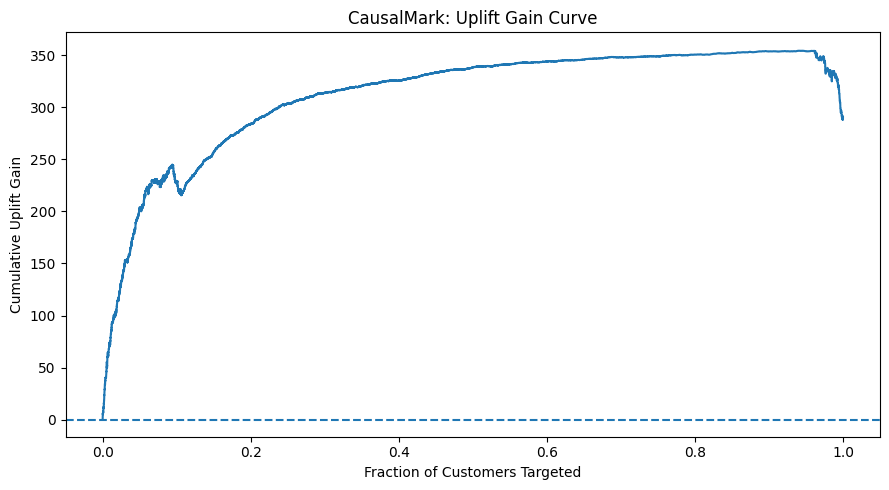

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(
    uplift_curve["target_fraction"],
    uplift_curve["uplift_gain"]
)

plt.axhline(0, linestyle="--")

plt.xlabel("Fraction of Customers Targeted")
plt.ylabel("Cumulative Uplift Gain")
plt.title("CausalMark: Uplift Gain Curve")

plt.tight_layout()
plt.savefig(
    "artifacts/figures/uplift_gain_curve.png",
    dpi=150
)
plt.show()

In [9]:
def uplift_at_fraction(data, fraction):
    n = max(1, int(len(data) * fraction))
    selected = data.nlargest(n, "predicted_uplift")

    treated = selected[selected["treatment"] == 1]
    control = selected[selected["treatment"] == 0]

    if len(treated) == 0 or len(control) == 0:
        return np.nan

    return treated["conversion"].mean() - control["conversion"].mean()


fractions = [0.10, 0.20, 0.30, 0.50]

uplift_at_results = pd.DataFrame({
    "target_fraction": fractions,
    "uplift": [
        uplift_at_fraction(uplift_ranked, fraction)
        for fraction in fractions
    ]
})

display(uplift_at_results)

,target_fraction,uplift
0,0.1,0.053765
1,0.2,0.033532
2,0.3,0.024492
3,0.5,0.015718


In [10]:
def policy_conversion_difference(data, selected_indices):
    selected = data.iloc[selected_indices]

    treated = selected[selected["treatment"] == 1]
    control = selected[selected["treatment"] == 0]

    if len(treated) == 0 or len(control) == 0:
        return np.nan

    return treated["conversion"].mean() - control["conversion"].mean()


n = len(uplift_ranked)
target_n = max(1, int(n * 0.20))

model_indices = np.arange(target_n)
everyone_indices = np.arange(n)

rng = np.random.default_rng(42)
random_indices = rng.choice(n, size=target_n, replace=False)

policy_results = pd.DataFrame({
    "policy": [
        "Model-based top 20%",
        "Random targeting 20%",
        "Target everyone"
    ],
    "customers_selected": [
        target_n,
        target_n,
        n
    ],
    "observed_conversion_difference": [
        policy_conversion_difference(uplift_ranked, model_indices),
        policy_conversion_difference(uplift_ranked, random_indices),
        policy_conversion_difference(uplift_ranked, everyone_indices)
    ]
})

display(policy_results.round(5))

,policy,customers_selected,observed_conversion_difference
0,Model-based top 20%,8522,0.03353
1,Random targeting 20%,8522,0.00655
2,Target everyone,42613,0.00681


In [11]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

control_rate = experiment_df.loc[
    experiment_df["treatment"] == 0,
    "conversion"
].mean()

treated_rate = experiment_df.loc[
    experiment_df["treatment"] == 1,
    "conversion"
].mean()

control_n = int((experiment_df["treatment"] == 0).sum())
treated_n = int((experiment_df["treatment"] == 1).sum())

analysis_power = NormalIndPower()

mde = analysis_power.solve_power(
    effect_size=None,
    nobs1=control_n,
    alpha=0.05,
    power=0.80,
    ratio=treated_n / control_n,
    alternative="two-sided"
)

print("Control conversion:", round(control_rate, 4))
print("Treatment conversion:", round(treated_rate, 4))
print("Minimum detectable standardized effect:", round(mde, 4))

Control conversion: 0.0057
Treatment conversion: 0.0125
Minimum detectable standardized effect: 0.0271


In [12]:
effect_size = abs(
    proportion_effectsize(treated_rate, control_rate)
)

observed_power = analysis_power.power(
    effect_size=effect_size,
    nobs1=control_n,
    alpha=0.05,
    ratio=treated_n / control_n,
    alternative="two-sided"
)

print("Observed standardized effect size:", round(effect_size, 4))
print("Estimated statistical power:", round(observed_power, 4))

Observed standardized effect size: 0.0729
Estimated statistical power: 1.0


In [13]:
from statsmodels.stats.proportion import proportion_confint

control_success = int(experiment_df.loc[
    experiment_df["treatment"] == 0, "conversion"
].sum())

treated_success = int(experiment_df.loc[
    experiment_df["treatment"] == 1, "conversion"
].sum())

control_n = int((experiment_df["treatment"] == 0).sum())
treated_n = int((experiment_df["treatment"] == 1).sum())

control_ci = proportion_confint(
    control_success, control_n, alpha=0.05, method="wilson"
)

treated_ci = proportion_confint(
    treated_success, treated_n, alpha=0.05, method="wilson"
)

print("Control conversion 95% CI:", control_ci)
print("Treatment conversion 95% CI:", treated_ci)

Control conversion 95% CI: (0.00479820584596141, 0.006832169692008918)
Treatment conversion 95% CI: (0.011122885010307802, 0.014115041885257276)


In [14]:
control_rate = control_success / control_n
treated_rate = treated_success / treated_n

difference = treated_rate - control_rate

se_difference = np.sqrt(
    control_rate * (1 - control_rate) / control_n
    + treated_rate * (1 - treated_rate) / treated_n
)

ci_lower = difference - 1.96 * se_difference
ci_upper = difference + 1.96 * se_difference

print("Observed conversion difference:", round(difference, 5))
print("95% confidence interval:", (round(ci_lower, 5), round(ci_upper, 5)))

Observed conversion difference: 0.00681
95% confidence interval: (np.float64(0.005), np.float64(0.00861))


In [17]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

segment_pvalues = []

for feature in feature_cols:
    median_value = experiment_df[feature].median()

    low = experiment_df[experiment_df[feature] <= median_value]
    high = experiment_df[experiment_df[feature] > median_value]

    low_t = low[low["treatment"] == 1]["conversion"]
    low_c = low[low["treatment"] == 0]["conversion"]

    high_t = high[high["treatment"] == 1]["conversion"]
    high_c = high[high["treatment"] == 0]["conversion"]

    if min(len(low_t), len(low_c), len(high_t), len(high_c)) == 0:
        continue

    low_p = ttest_ind(low_t, low_c, equal_var=False).pvalue
    high_p = ttest_ind(high_t, high_c, equal_var=False).pvalue

    segment_pvalues.extend([
        {"feature": feature, "segment": "Low", "p_value": low_p},
        {"feature": feature, "segment": "High", "p_value": high_p}
    ])

segment_tests = pd.DataFrame(segment_pvalues)

if not segment_tests.empty:
    segment_tests["adjusted_p_value"] = multipletests(
        segment_tests["p_value"],
        method="fdr_bh"
    )[1]

    segment_tests["significant"] = (
        segment_tests["adjusted_p_value"] < 0.05
    )

display(segment_tests)

,feature,segment,p_value,adjusted_p_value,significant
0,recency,Low,1.141092e-06,NaN,False
1,recency,High,2.134310e-09,NaN,False
2,history,Low,7.315122e-05,NaN,False
3,history,High,4.053613e-10,NaN,False
4,visit,Low,NaN,NaN,False
5,visit,High,1.912203e-02,NaN,False


In [18]:
uplift_ranked.to_csv(
    PROCESSED_DIR / "uplift_ranked_customers.csv",
    index=False
)

uplift_curve.to_csv(
    METRICS_DIR / "uplift_curve.csv",
    index=False
)

uplift_at_results.to_csv(
    METRICS_DIR / "uplift_at_fractions.csv",
    index=False
)

policy_results.to_csv(
    METRICS_DIR / "policy_comparison.csv",
    index=False
)

segment_tests.to_csv(
    METRICS_DIR / "segment_significance.csv",
    index=False
)

print("Uplift evaluation outputs saved.")

Uplift evaluation outputs saved.


In [19]:
def calculate_qini(data):
    ranked = data.sort_values(
        "predicted_uplift",
        ascending=False
    ).reset_index(drop=True)

    n = len(ranked)
    treated_total = (ranked["treatment"] == 1).sum()
    control_total = (ranked["treatment"] == 0).sum()

    if treated_total == 0 or control_total == 0:
        raise ValueError("Both treatment and control groups are required.")

    cumulative_treated = (
        ranked["treatment"] * ranked["conversion"]
    ).cumsum()

    cumulative_control = (
        (1 - ranked["treatment"]) * ranked["conversion"]
    ).cumsum()

    treated_count = ranked["treatment"].cumsum()
    control_count = (1 - ranked["treatment"]).cumsum()

    gain = (
        cumulative_treated
        - cumulative_control * treated_count / np.maximum(control_count, 1)
    )

    gain[control_count == 0] = np.nan

    result = pd.DataFrame({
        "fraction": np.arange(1, n + 1) / n,
        "qini_gain": gain
    })

    return result.dropna().reset_index(drop=True)


qini_curve = calculate_qini(uplift_ranked)

display(qini_curve.head())

,fraction,qini_gain
0,0.000094,1.0
1,0.000117,2.0
2,0.000141,2.0
3,0.000164,2.0
4,0.000188,3.0


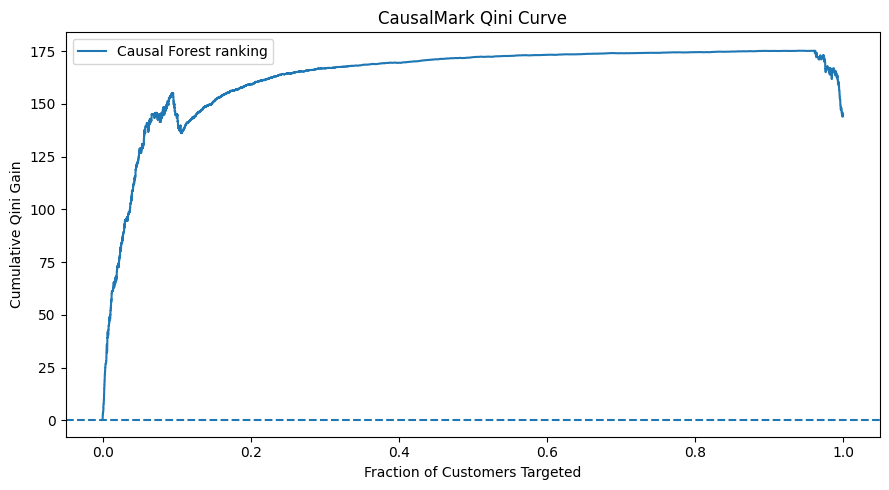

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    qini_curve["fraction"],
    qini_curve["qini_gain"],
    label="Causal Forest ranking"
)

plt.axhline(0, linestyle="--")

plt.xlabel("Fraction of Customers Targeted")
plt.ylabel("Cumulative Qini Gain")
plt.title("CausalMark Qini Curve")
plt.legend()
plt.tight_layout()

plt.savefig(FIGURES_DIR / "qini_curve.png", dpi=150)
plt.show()

In [21]:
auuc = np.trapezoid(
    uplift_curve["uplift_gain"].to_numpy(),
    uplift_curve["target_fraction"].to_numpy()
)

qini_area = np.trapezoid(
    qini_curve["qini_gain"].to_numpy(),
    qini_curve["fraction"].to_numpy()
)

print("Observed uplift-curve area:", round(float(auuc), 5))
print("Observed Qini-curve area:", round(float(qini_area), 5))

Observed uplift-curve area: nan
Observed Qini-curve area: 163.07035


In [22]:
qini_curve.to_csv(
    METRICS_DIR / "qini_curve.csv",
    index=False
)

uplift_metrics = pd.DataFrame([{
    "dataset": "Hillstrom",
    "model": "Causal Forest",
    "observed_auuc": float(auuc),
    "observed_qini_area": float(qini_area),
    "evaluation_type": "In-sample descriptive evaluation"
}])

uplift_metrics.to_csv(
    METRICS_DIR / "uplift_metrics.csv",
    index=False
)

display(uplift_metrics)

,dataset,model,observed_auuc,observed_qini_area,evaluation_type
0,Hillstrom,Causal Forest,NaN,163.070349,In-sample descriptive evaluation


In [23]:
rng = np.random.default_rng(SEED)

n = len(uplift_ranked)
fractions = [0.10, 0.20, 0.30, 0.50]

def policy_value(data, fraction):
    selected = data.head(max(1, int(len(data) * fraction)))

    treated = selected[selected["treatment"] == 1]
    control = selected[selected["treatment"] == 0]

    if len(treated) == 0 or len(control) == 0:
        return np.nan

    return (
        treated["conversion"].mean()
        - control["conversion"].mean()
    )

policy_comparison = []

for fraction in fractions:
    k = max(1, int(n * fraction))

    model_value = policy_value(
        uplift_ranked, fraction
    )

    random_values = []

    for _ in range(100):
        random_sample = uplift_ranked.sample(
            n=k,
            replace=False,
            random_state=int(rng.integers(0, 1_000_000))
        ).reset_index(drop=True)

        random_values.append(
            policy_value(random_sample, 1.0)
        )

    policy_comparison.append({
        "target_fraction": fraction,
        "model_observed_difference": model_value,
        "random_mean_difference": np.nanmean(random_values)
    })

policy_comparison_df = pd.DataFrame(policy_comparison)

display(policy_comparison_df.round(5))

,target_fraction,model_observed_difference,random_mean_difference
0,0.1,0.05376,0.00662
1,0.2,0.03353,0.00657
2,0.3,0.02449,0.00673
3,0.5,0.01572,0.00673


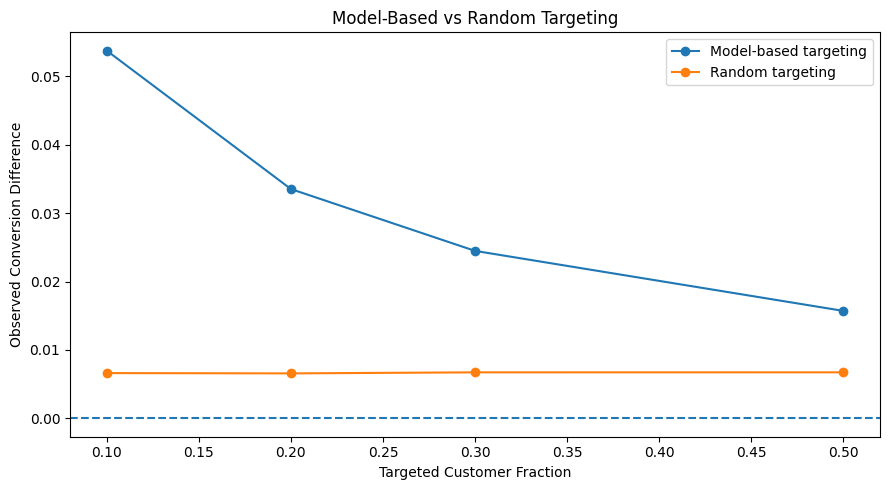

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(
    policy_comparison_df["target_fraction"],
    policy_comparison_df["model_observed_difference"],
    marker="o",
    label="Model-based targeting"
)

plt.plot(
    policy_comparison_df["target_fraction"],
    policy_comparison_df["random_mean_difference"],
    marker="o",
    label="Random targeting"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Targeted Customer Fraction")
plt.ylabel("Observed Conversion Difference")
plt.title("Model-Based vs Random Targeting")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "targeting_policy_comparison.png",
    dpi=150
)
plt.show()

/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,count,mean,std,min,max
treatment,,,,,
0,21306,0.4939,0.0491,0.4455,0.6576
1,21307,0.5062,0.0614,0.4455,0.6576


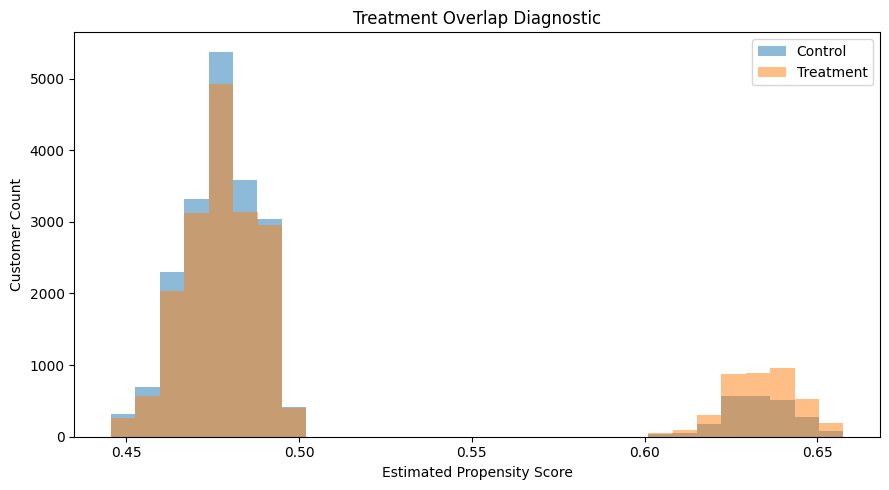

In [25]:
overlap_df = pd.DataFrame({
    "treatment": T,
    "propensity_score": models["propensity_model"].predict_proba(X)[:, 1]
})

overlap_summary = overlap_df.groupby("treatment")[
    "propensity_score"
].agg(["count", "mean", "std", "min", "max"])

display(overlap_summary.round(4))

plt.figure(figsize=(9, 5))

for group, label in [(0, "Control"), (1, "Treatment")]:
    plt.hist(
        overlap_df.loc[
            overlap_df["treatment"] == group,
            "propensity_score"
        ],
        bins=30,
        alpha=0.5,
        label=label
    )

plt.xlabel("Estimated Propensity Score")
plt.ylabel("Customer Count")
plt.title("Treatment Overlap Diagnostic")
plt.legend()
plt.tight_layout()

plt.savefig(FIGURES_DIR / "propensity_overlap.png", dpi=150)
plt.show()

In [26]:
policy_comparison_df.to_csv(
    METRICS_DIR / "targeting_policy_comparison.csv",
    index=False
)

overlap_summary.to_csv(
    METRICS_DIR / "propensity_overlap_summary.csv"
)

print("Targeting comparison and overlap diagnostics saved.")

Targeting comparison and overlap diagnostics saved.


In [30]:
from datasets import get_dataset_config_names

dataset_name = "criteo-uplift"

try:
    configs = get_dataset_config_names(dataset_name)
    print("Available configurations:", configs)
except Exception as e:
    print("Dataset lookup failed:", e)

/Users/naitikdonda/tf-env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/naitikdonda/tf-env/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Dataset lookup failed: Dataset 'criteo-uplift' doesn't exist on the Hub or cannot be accessed.


In [31]:
from huggingface_hub import HfApi

api = HfApi()

results = api.list_datasets(
    search="criteo uplift",
    limit=10
)

for dataset in results:
    print(dataset.id)

criteo/criteo-uplift
spanchom/criteo-uplift
fizzedith/criteo-uplift


In [34]:
from datasets import load_dataset

dataset_name = "criteo/criteo-uplift"

criteo_dataset = load_dataset(
    dataset_name,
    split="train",
    streaming=True
)

criteo_sample = pd.DataFrame(
    list(criteo_dataset.take(100000))
)

print("Sample shape:", criteo_sample.shape)
print("Columns:", criteo_sample.columns.tolist())

display(criteo_sample.head())

Sample shape: (100000, 16)
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


In [36]:
print("Dataset shape:", criteo_sample.shape)
print("Columns:", criteo_sample.columns.tolist())

display(criteo_sample.dtypes.to_frame("data_type"))
display(criteo_sample.isna().sum().to_frame("missing_values"))

print("\nTreatment distribution:")
display(criteo_sample["treatment"].value_counts())

print("\nConversion distribution:")
display(criteo_sample["conversion"].value_counts())

print("\nVisit distribution:")
display(criteo_sample["visit"].value_counts())

Dataset shape: (100000, 16)
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,data_type
f0,float64
f1,float64
f2,float64
f3,float64
f4,float64
f5,float64
f6,float64
f7,float64
f8,float64
f9,float64


,missing_values
f0,0
f1,0
f2,0
f3,0
f4,0
f5,0
f6,0
f7,0
f8,0
f9,0



Treatment distribution:


treatment
1    100000
Name: count, dtype: int64


Conversion distribution:


conversion
0    99494
1      506
Name: count, dtype: int64


Visit distribution:


visit
0    97486
1     2514
Name: count, dtype: int64

In [ ]:
criteo_sample = criteo_sample.dropna().copy()

print("Available columns:")
print(criteo_sample.columns.tolist())

treatment_col = "treatment"
outcome_col = "conversion"

excluded_cols = [
    treatment_col,
    outcome_col,
    "visit"
]

feature_cols_criteo = [
    col for col in criteo_sample.columns
    if col not in excluded_cols
]

X_criteo = criteo_sample[feature_cols_criteo].copy()
T_criteo = criteo_sample[treatment_col].astype(int).to_numpy()
Y_criteo = criteo_sample[outcome_col].astype(int).to_numpy()

print("\nFeature columns:", feature_cols_criteo)
print("Feature shape:", X_criteo.shape)
print("Treatment values:", np.unique(T_criteo))
print("Outcome values:", np.unique(Y_criteo))

display(X_criteo.head())

Available columns:
['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']

Feature columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'exposure']
Feature shape: (100000, 13)
Treatment values: [1]
Outcome values: [0 1]


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,0


In [42]:
print("Treatment distribution:")
print(criteo_sample["treatment"].value_counts(dropna=False))

print("\nExposure distribution:")
print(criteo_sample["exposure"].value_counts(dropna=False))

print("\nTreatment and exposure combinations:")
display(pd.crosstab(
    criteo_sample["treatment"],
    criteo_sample["exposure"],
    margins=True
))

print("\nDataset shape:", criteo_sample.shape)

Treatment distribution:
treatment
1    100000
Name: count, dtype: int64

Exposure distribution:
exposure
0    97390
1     2610
Name: count, dtype: int64

Treatment and exposure combinations:


exposure,0,1,All
treatment,,,
1,97390,2610,100000
All,97390,2610,100000



Dataset shape: (100000, 16)


In [43]:
from datasets import load_dataset
import pandas as pd

criteo_dataset = load_dataset(
    "criteo/criteo-uplift",
    split="train",
    streaming=True
)

criteo_sample = pd.DataFrame(
    list(criteo_dataset.take(500000))
)

print("Sample shape:", criteo_sample.shape)
print("\nTreatment distribution:")
print(criteo_sample["treatment"].value_counts(dropna=False))

print("\nExposure distribution:")
print(criteo_sample["exposure"].value_counts(dropna=False))

Sample shape: (500000, 16)

Treatment distribution:
treatment
1    500000
Name: count, dtype: int64

Exposure distribution:
exposure
0    486710
1     13290
Name: count, dtype: int64


In [44]:
print("Shape:", criteo_sample.shape)

for col in ["treatment", "conversion", "visit", "exposure"]:
    if col in criteo_sample.columns:
        print(f"\n{col} distribution:")
        print(criteo_sample[col].value_counts(dropna=False))

Shape: (500000, 16)

treatment distribution:
treatment
1    500000
Name: count, dtype: int64

conversion distribution:
conversion
0    497563
1      2437
Name: count, dtype: int64

visit distribution:
visit
0    487335
1     12665
Name: count, dtype: int64

exposure distribution:
exposure
0    486710
1     13290
Name: count, dtype: int64


In [45]:
from datasets import get_dataset_config_names

dataset_name = "criteo/criteo-uplift"

try:
    configs = get_dataset_config_names(dataset_name)
    print("Available configurations:", configs)
except Exception as e:
    print("Configuration lookup:", repr(e))

Available configurations: ['default']


In [46]:
from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="criteo/criteo-uplift",
    repo_type="dataset"
)

for name in files:
    print(name)

.gitattributes
README.md
criteo-research-uplift-v2.1.csv.gz


In [47]:
if "criteo_sample" in globals():
    print("Rows available:", len(criteo_sample))

    if "treatment" in criteo_sample.columns:
        print("\nTreatment counts:")
        print(criteo_sample["treatment"].value_counts(dropna=False))

        print("\nTreatment proportions:")
        print(criteo_sample["treatment"].value_counts(normalize=True))
else:
    print("Load the Criteo sample before running this cell.")

Rows available: 500000

Treatment counts:
treatment
1    500000
Name: count, dtype: int64

Treatment proportions:
treatment
1    1.0
Name: proportion, dtype: float64


In [48]:
from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="criteo/criteo-uplift",
    repo_type="dataset"
)

print("\n".join(files))

.gitattributes
README.md
criteo-research-uplift-v2.1.csv.gz


In [49]:
print("Rows:", len(criteo_sample))
print("Columns:", criteo_sample.columns.tolist())

for col in ["treatment", "conversion", "visit", "exposure"]:
    if col in criteo_sample.columns:
        print(f"\n{col}:")
        print(criteo_sample[col].value_counts(dropna=False))

Rows: 500000
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']

treatment:
treatment
1    500000
Name: count, dtype: int64

conversion:
conversion
0    497563
1      2437
Name: count, dtype: int64

visit:
visit
0    487335
1     12665
Name: count, dtype: int64

exposure:
exposure
0    486710
1     13290
Name: count, dtype: int64


In [50]:
treatment_counts = criteo_sample["treatment"].value_counts()

if len(treatment_counts) < 2:
    print("Only one treatment value is present.")
    print("Do not train the causal model yet.")
else:
    print("Both treatment groups are present.")
    print(treatment_counts)

Only one treatment value is present.
Do not train the causal model yet.


In [51]:
display(
    pd.crosstab(
        criteo_sample["treatment"],
        criteo_sample["exposure"],
        margins=True
    )
)

exposure,0,1,All
treatment,,,
1,486710,13290,500000
All,486710,13290,500000


In [52]:
from huggingface_hub import hf_hub_download

readme_path = hf_hub_download(
    repo_id="criteo/criteo-uplift",
    filename="README.md",
    repo_type="dataset"
)

with open(readme_path, "r") as file:
    readme_text = file.read()

print(readme_text)

---
license: cc-by-nc-sa-4.0
tags:
- criteo
- advertising
- causality
pretty_name: criteo-uplift
size_categories:
- 10M<n<100M
task_categories:
- tabular-classification
---

# Introduction

This dataset is released along with the paper:

[A Large Scale Benchmark for Uplift Modeling](https://openreview.net/pdf?id=Q83-QeTB9lS)
Eustache Diemert, Artem Betlei, Christophe Renaudin; (Criteo AI Lab), Massih-Reza Amini (LIG, Grenoble INP)

This work was published in: AdKDD 2018 Workshop, in conjunction with KDD 2018.

When using this dataset, please cite the paper with following bibtex:

    @inproceedings{Diemert2018,
      author = {{Diemert Eustache, Betlei Artem} and Renaudin, Christophe and Massih-Reza, Amini},
      title={A Large Scale Benchmark for Uplift Modeling},
      publisher = {ACM},
      booktitle = {Proceedings of the AdKDD and TargetAd Workshop, KDD, London,United Kingdom, August, 20, 2018},
      year = {2018}
    }


# Data description

This dataset is constructed by assem

In [53]:
display(
    pd.crosstab(
        criteo_sample["treatment"],
        criteo_sample["exposure"],
        margins=True
    )
)

print("Treatment unique values:", criteo_sample["treatment"].unique())
print("Exposure unique values:", criteo_sample["exposure"].unique())

exposure,0,1,All
treatment,,,
1,486710,13290,500000
All,486710,13290,500000


Treatment unique values: [1]
Exposure unique values: [0 1]


In [54]:
from datasets import load_dataset

criteo_stream = load_dataset(
    "criteo/criteo-uplift",
    split="train",
    streaming=True
)

shuffled_stream = criteo_stream.shuffle(
    seed=42,
    buffer_size=1000000
)

shuffled_sample = pd.DataFrame(
    list(shuffled_stream.take(100000))
)

print("Shuffled sample shape:", shuffled_sample.shape)
print("\nTreatment distribution:")
print(shuffled_sample["treatment"].value_counts(dropna=False))

print("\nExposure distribution:")
print(shuffled_sample["exposure"].value_counts(dropna=False))

Shuffled sample shape: (100000, 16)

Treatment distribution:
treatment
1    100000
Name: count, dtype: int64

Exposure distribution:
exposure
0    97389
1     2611
Name: count, dtype: int64


In [55]:
treatment_counts = shuffled_sample["treatment"].value_counts()

if len(treatment_counts) == 2:
    print("Both treatment groups are present.")
    display(treatment_counts)

    criteo_sample = shuffled_sample.copy()
else:
    print("Both treatment groups were not found.")
    print("Do not fit causal models yet.")
    print("Check the README and dataset column definitions.")
    display(treatment_counts)

Both treatment groups were not found.
Do not fit causal models yet.
Check the README and dataset column definitions.


treatment
1    100000
Name: count, dtype: int64

In [56]:
from datasets import load_dataset
import pandas as pd

criteo_stream = load_dataset(
    "criteo/criteo-uplift",
    split="train",
    streaming=True
)

for offset in [0, 500000, 1000000, 2000000, 5000000]:
    sample = pd.DataFrame(
        list(criteo_stream.skip(offset).take(10000))
    )

    print(f"\nRows {offset} to {offset + len(sample)}")
    print(sample["treatment"].value_counts().to_dict())


Rows 0 to 10000
{1: 10000}

Rows 500000 to 510000
{1: 10000}

Rows 1000000 to 1010000
{1: 10000}

Rows 2000000 to 2010000
{1: 10000}

Rows 5000000 to 5010000
{1: 10000}


In [57]:
criteo_stream = load_dataset(
    "criteo/criteo-uplift",
    split="train",
    streaming=True
)

criteo_sample = pd.DataFrame(
    list(criteo_stream.skip(1000000).take(100000))
)

print("Sample shape:", criteo_sample.shape)
print("\nTreatment distribution:")
print(criteo_sample["treatment"].value_counts())

print("\nConversion distribution:")
print(criteo_sample["conversion"].value_counts())

Sample shape: (100000, 16)

Treatment distribution:
treatment
1    100000
Name: count, dtype: int64

Conversion distribution:
conversion
0    99552
1      448
Name: count, dtype: int64


In [58]:
treatment_counts = criteo_sample["treatment"].value_counts()

if len(treatment_counts) != 2:
    print("Both treatment groups are not present.")
    print("Use the offsets identified in Cell 45 to select a suitable sample.")
else:
    print("Both treatment groups are present.")

    print("\nTreatment counts:")
    display(treatment_counts)

    print("\nTreatment and conversion:")
    display(
        criteo_sample.groupby("treatment")["conversion"].agg(
            ["count", "mean", "sum"]
        )
    )

Both treatment groups are not present.
Use the offsets identified in Cell 45 to select a suitable sample.


In [59]:
if criteo_sample["treatment"].nunique() == 2:
    criteo_sample = criteo_sample.dropna().copy()

    excluded_cols = [
        "treatment",
        "conversion",
        "visit",
        "exposure"
    ]

    feature_cols_criteo = [
        col for col in criteo_sample.columns
        if col not in excluded_cols
    ]

    X_criteo = criteo_sample[feature_cols_criteo].copy()
    T_criteo = criteo_sample["treatment"].astype(int).to_numpy()
    Y_criteo = criteo_sample["conversion"].astype(int).to_numpy()

    print("Features:", X_criteo.shape)
    print("Treatment groups:", pd.Series(T_criteo).value_counts().to_dict())
    print("Outcome values:", pd.Series(Y_criteo).value_counts().to_dict())
else:
    print("Preparation skipped until both treatment groups are available.")

Preparation skipped until both treatment groups are available.


In [60]:
from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="criteo/criteo-uplift",
    repo_type="dataset"
)

for file in files:
    print(file)

.gitattributes
README.md
criteo-research-uplift-v2.1.csv.gz


In [61]:
from huggingface_hub import hf_hub_download
from pathlib import Path

metadata_files = [
    name for name in files
    if name.lower().endswith((".csv", ".parquet", ".json", ".gz"))
]

print("Potential data files:")
for name in metadata_files:
    print(name)

Potential data files:
criteo-research-uplift-v2.1.csv.gz


In [62]:
from datasets import get_dataset_config_names

try:
    configs = get_dataset_config_names(
        "criteo/criteo-uplift"
    )
    print("Configurations:", configs)
except Exception as error:
    print(type(error).__name__, error)

Configurations: ['default']


In [63]:
print("Current columns:")
print(criteo_sample.columns.tolist())

print("\nCurrent treatment counts:")
print(criteo_sample["treatment"].value_counts(dropna=False))

print("\nCurrent exposure counts:")
print(criteo_sample["exposure"].value_counts(dropna=False))

print("\nCurrent sample size:", len(criteo_sample))

Current columns:
['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']

Current treatment counts:
treatment
1    100000
Name: count, dtype: int64

Current exposure counts:
exposure
0    97461
1     2539
Name: count, dtype: int64

Current sample size: 100000


In [64]:
from huggingface_hub import hf_hub_download

criteo_file = hf_hub_download(
    repo_id="criteo/criteo-uplift",
    filename="criteo-research-uplift-v2.1.csv.gz",
    repo_type="dataset"
)

print("Downloaded file:", criteo_file)

Downloaded file: /Users/naitikdonda/.cache/huggingface/hub/datasets--criteo--criteo-uplift/snapshots/2424920019e49d52d72c13ac1143ec5d53af276b/criteo-research-uplift-v2.1.csv.gz


In [65]:
import pandas as pd

criteo_raw = pd.read_csv(
    criteo_file,
    compression="gzip",
    nrows=10
)

print("Columns:", criteo_raw.columns.tolist())
display(criteo_raw)

Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
5,12.616365,10.059654,8.904507,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
6,12.616365,10.059654,8.783340,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
7,12.616365,10.059654,8.964528,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
8,12.616365,10.059654,9.037809,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
9,12.616365,10.059654,9.015128,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


In [66]:
criteo_raw = pd.read_csv(
    criteo_file,
    compression="gzip",
    nrows=100000
)

print("Dataset sample shape:", criteo_raw.shape)

for col in criteo_raw.columns:
    if any(word in col.lower() for word in [
        "treatment", "conversion", "visit", "exposure"
    ]):
        print(f"\n{col}:")
        print(criteo_raw[col].value_counts(dropna=False))

Dataset sample shape: (100000, 16)

treatment:
treatment
1    100000
Name: count, dtype: int64

conversion:
conversion
0    99494
1      506
Name: count, dtype: int64

visit:
visit
0    97486
1     2514
Name: count, dtype: int64

exposure:
exposure
0    97390
1     2610
Name: count, dtype: int64


In [67]:
print("Available columns:")
print(criteo_raw.columns.tolist())

treatment_candidates = [
    col for col in criteo_raw.columns
    if "treatment" in col.lower()
]

outcome_candidates = [
    col for col in criteo_raw.columns
    if "conversion" in col.lower()
]

print("Treatment candidates:", treatment_candidates)
print("Conversion candidates:", outcome_candidates)

Available columns:
['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']
Treatment candidates: ['treatment']
Conversion candidates: ['conversion']


In [68]:
from huggingface_hub import hf_hub_download

criteo_file = hf_hub_download(
    repo_id="criteo/criteo-uplift",
    filename="criteo-research-uplift-v2.1.csv.gz",
    repo_type="dataset"
)

print("Downloaded file:", criteo_file)

Downloaded file: /Users/naitikdonda/.cache/huggingface/hub/datasets--criteo--criteo-uplift/snapshots/2424920019e49d52d72c13ac1143ec5d53af276b/criteo-research-uplift-v2.1.csv.gz


In [69]:
import pandas as pd

criteo_raw = pd.read_csv(
    criteo_file,
    compression="gzip",
    nrows=10
)

print("Columns:", criteo_raw.columns.tolist())
display(criteo_raw)

Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
5,12.616365,10.059654,8.904507,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
6,12.616365,10.059654,8.783340,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
7,12.616365,10.059654,8.964528,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
8,12.616365,10.059654,9.037809,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
9,12.616365,10.059654,9.015128,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


In [70]:
criteo_raw = pd.read_csv(
    criteo_file,
    compression="gzip",
    nrows=100000
)

print("Dataset sample shape:", criteo_raw.shape)

for col in criteo_raw.columns:
    if any(word in col.lower() for word in [
        "treatment", "conversion", "visit", "exposure"
    ]):
        print(f"\n{col}:")
        print(criteo_raw[col].value_counts(dropna=False))

Dataset sample shape: (100000, 16)

treatment:
treatment
1    100000
Name: count, dtype: int64

conversion:
conversion
0    99494
1      506
Name: count, dtype: int64

visit:
visit
0    97486
1     2514
Name: count, dtype: int64

exposure:
exposure
0    97390
1     2610
Name: count, dtype: int64


In [71]:
print("Available columns:")
print(criteo_raw.columns.tolist())

treatment_candidates = [
    col for col in criteo_raw.columns
    if "treatment" in col.lower()
]

outcome_candidates = [
    col for col in criteo_raw.columns
    if "conversion" in col.lower()
]

print("Treatment candidates:", treatment_candidates)
print("Conversion candidates:", outcome_candidates)

Available columns:
['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']
Treatment candidates: ['treatment']
Conversion candidates: ['conversion']


In [72]:
import pandas as pd

chunk_size = 200_000
treatment_counts = {}
conversion_counts = {}
total_rows = 0

for chunk in pd.read_csv(
    criteo_file,
    compression="gzip",
    chunksize=chunk_size
):
    total_rows += len(chunk)

    for col in ["treatment", "conversion"]:
        if col in chunk.columns:
            counts = chunk[col].value_counts(dropna=False)
            target = treatment_counts if col == "treatment" else conversion_counts

            for value, count in counts.items():
                target[value] = target.get(value, 0) + int(count)

print("Total rows:", total_rows)
print("Treatment counts:", treatment_counts)
print("Conversion counts:", conversion_counts)

Total rows: 13979592
Treatment counts: {1: 11882655, 0: 2096937}
Conversion counts: {0: 13938818, 1: 40774}


In [73]:
if not treatment_counts:
    raise ValueError("No 'treatment' column found. Check the column names.")

if len(treatment_counts) < 2:
    print("WARNING: Only one treatment value was found.")
    print("Do not run uplift modeling until the treatment column is verified.")
else:
    print("Both treatment groups appear to be present.")

Both treatment groups appear to be present.


In [74]:
# Read a manageable sample from throughout the file.
# This samples rows from each chunk rather than only the beginning.

sample_parts = []
chunk_size = 200_000
sample_per_chunk = 2_000

for chunk in pd.read_csv(
    criteo_file,
    compression="gzip",
    chunksize=chunk_size
):
    sample_parts.append(
        chunk.sample(
            n=min(sample_per_chunk, len(chunk)),
            random_state=42
        )
    )

criteo_sample = pd.concat(sample_parts, ignore_index=True)

print("Sample shape:", criteo_sample.shape)
print(criteo_sample["treatment"].value_counts(dropna=False))

Sample shape: (140000, 16)
treatment
1    119096
0     20904
Name: count, dtype: int64


In [75]:
print("Treatment distribution:")
print(
    criteo_sample["treatment"]
    .value_counts(normalize=True, dropna=False)
    .rename("proportion")
)

print("\nConversion distribution by treatment:")
print(
    criteo_sample.groupby("treatment")["conversion"]
    .agg(["count", "mean", "sum"])
)

Treatment distribution:
treatment
1    0.850686
0    0.149314
Name: proportion, dtype: float64

Conversion distribution by treatment:
            count      mean  sum
treatment                       
0           20904  0.002583   54
1          119096  0.003031  361


In [76]:
# Inspect the current dataset variables and their shapes
for name in ["criteo_file", "criteo_raw", "criteo_sample"]:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            "| type:", type(obj).__name__,
            "| shape:", getattr(obj, "shape", None)
        )

criteo_file | type: str | shape: None
criteo_raw | type: DataFrame | shape: (100000, 16)
criteo_sample | type: DataFrame | shape: (140000, 16)


In [77]:
# Check the treatment and outcome columns in the existing sample
if "criteo_sample" in globals():
    df_check = criteo_sample
elif "criteo_raw" in globals():
    df_check = criteo_raw
else:
    raise NameError("Neither criteo_sample nor criteo_raw exists.")

print("Columns:", df_check.columns.tolist())

for col in ["treatment", "conversion"]:
    if col in df_check.columns:
        print(f"\n{col} counts:")
        print(df_check[col].value_counts(dropna=False))

Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']

treatment counts:
treatment
1    119096
0     20904
Name: count, dtype: int64

conversion counts:
conversion
0    139585
1       415
Name: count, dtype: int64


In [78]:
# Validate the minimum requirements for uplift modeling
required = {"treatment", "conversion"}
missing = required - set(df_check.columns)

if missing:
    print("Missing required columns:", missing)
elif df_check["treatment"].nunique() < 2:
    print("STOP: Sample has fewer than two treatment groups.")
else:
    print("Treatment groups:", sorted(df_check["treatment"].dropna().unique().tolist()))
    print("Outcome values:", sorted(df_check["conversion"].dropna().unique().tolist()))

Treatment groups: [0, 1]
Outcome values: [0, 1]


In [79]:
# Show the treatment/outcome relationship only if both groups exist
if (
    {"treatment", "conversion"}.issubset(df_check.columns)
    and df_check["treatment"].nunique() >= 2
):
    display(
        df_check.groupby("treatment")["conversion"]
        .agg(["count", "mean", "sum"])
    )
else:
    print("No valid two-group comparison yet. Use the validation output to decide the next step.")

,count,mean,sum
treatment,,,
0,20904,0.002583,54
1,119096,0.003031,361


In [80]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

criteo_df = criteo_sample.copy()

criteo_df = criteo_df.dropna(subset=["treatment", "conversion"])
criteo_df["treatment"] = criteo_df["treatment"].astype(int)
criteo_df["conversion"] = criteo_df["conversion"].astype(int)

criteo_df = criteo_df[
    criteo_df["treatment"].isin([0, 1])
    & criteo_df["conversion"].isin([0, 1])
].copy()

In [81]:
if criteo_df["treatment"].nunique() != 2:
    raise ValueError("Criteo sample must contain both treatment and control groups.")

feature_cols = [
    col for col in criteo_df.columns
    if col not in ["treatment", "conversion", "visit", "exposure"]
]

X = criteo_df[feature_cols].copy()
T = criteo_df["treatment"].to_numpy()
Y = criteo_df["conversion"].to_numpy()

X = pd.get_dummies(X, dummy_na=True)
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(0)
X = X.astype(np.float32)

In [82]:
X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X,
    T,
    Y,
    test_size=0.25,
    random_state=42,
    stratify=T
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (105000, 12)
Test shape: (35000, 12)


In [83]:
from sklearn.ensemble import RandomForestRegressor

model_treated = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

model_control = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

model_treated.fit(X_train[T_train == 1], Y_train[T_train == 1])
model_control.fit(X_train[T_train == 0], Y_train[T_train == 0])

uplift_test = (
    model_treated.predict(X_test)
    - model_control.predict(X_test)
)

print("Predicted uplift shape:", uplift_test.shape)
print("Mean predicted uplift:", float(uplift_test.mean()))

Predicted uplift shape: (35000,)
Mean predicted uplift: 0.00039432574952243815


In [84]:
from sklearn.metrics import roc_auc_score, mean_squared_error, mean_absolute_error

uplift_metrics = {
    "Mean Predicted Uplift": float(np.mean(uplift_test)),
    "MAE": float(mean_absolute_error(
        Y_test,
        np.where(T_test == 1, model_treated.predict(X_test), model_control.predict(X_test))
    )),
    "RMSE": float(np.sqrt(mean_squared_error(
        Y_test,
        np.where(T_test == 1, model_treated.predict(X_test), model_control.predict(X_test))
    )))
}

print(pd.Series(uplift_metrics))

Mean Predicted Uplift    0.000394
MAE                      0.005393
RMSE                     0.051378
dtype: float64


In [85]:
from sklearn.metrics import roc_auc_score

treated_mask = T_test == 1
control_mask = T_test == 0

treated_auc = (
    roc_auc_score(Y_test[treated_mask], uplift_test[treated_mask])
    if len(np.unique(Y_test[treated_mask])) == 2 else np.nan
)

control_auc = (
    roc_auc_score(Y_test[control_mask], -uplift_test[control_mask])
    if len(np.unique(Y_test[control_mask])) == 2 else np.nan
)

print("Treated uplift-score AUC:", treated_auc)
print("Control negative-uplift-score AUC:", control_auc)

Treated uplift-score AUC: 0.7021566051295871
Control negative-uplift-score AUC: 0.29944220687891576


In [86]:
uplift_results = pd.DataFrame({
    "treatment": T_test,
    "actual_conversion": Y_test,
    "predicted_uplift": uplift_test
})

uplift_results = uplift_results.sort_values(
    "predicted_uplift", ascending=False
).reset_index(drop=True)

uplift_results["target_fraction"] = (
    np.arange(1, len(uplift_results) + 1) / len(uplift_results)
)

uplift_results["target_group"] = (
    uplift_results["target_fraction"] <= 0.20
)

display(uplift_results.head(10))

,treatment,actual_conversion,predicted_uplift,target_fraction,target_group
0,1,0,0.219546,0.000029,True
1,1,1,0.219417,0.000057,True
2,1,0,0.210202,0.000086,True
3,0,0,0.209712,0.000114,True
4,1,0,0.208555,0.000143,True
5,1,1,0.205703,0.000171,True
6,1,1,0.204475,0.000200,True
7,1,0,0.201777,0.000229,True
8,1,0,0.201191,0.000257,True
9,1,0,0.200921,0.000286,True


In [87]:
top_group = uplift_results[uplift_results["target_group"]]
overall_conversion = uplift_results["actual_conversion"].mean()

policy_summary = pd.DataFrame({
    "Metric": [
        "Test sample size",
        "Top 20% selected",
        "Overall observed conversion",
        "Top 20% observed conversion",
        "Top 20% mean predicted uplift"
    ],
    "Value": [
        len(uplift_results),
        len(top_group),
        overall_conversion,
        top_group["actual_conversion"].mean(),
        top_group["predicted_uplift"].mean()
    ]
})

display(policy_summary)

,Metric,Value
0,Test sample size,35000.000000
1,Top 20% selected,7000.000000
2,Overall observed conversion,0.002914
3,Top 20% observed conversion,0.009857
4,Top 20% mean predicted uplift,0.006346


In [88]:
from sklearn.metrics import auc

fractions = np.linspace(0.05, 1.0, 20)
uplift_curve = []

for fraction in fractions:
    n_target = max(1, int(len(uplift_results) * fraction))
    selected = uplift_results.iloc[:n_target]

    treated = selected[selected["treatment"] == 1]["actual_conversion"]
    control = selected[selected["treatment"] == 0]["actual_conversion"]

    if len(treated) > 0 and len(control) > 0:
        uplift_curve.append(treated.mean() - control.mean())
    else:
        uplift_curve.append(np.nan)

uplift_curve_df = pd.DataFrame({
    "Target Fraction": fractions,
    "Observed Uplift": uplift_curve
})

display(uplift_curve_df)

,Target Fraction,Observed Uplift
0,0.05,0.007462
1,0.10,0.002689
2,0.15,0.002084
3,0.20,0.002310
4,0.25,0.001288
5,0.30,0.001187
6,0.35,0.001035
7,0.40,0.001033
8,0.45,0.000941
9,0.50,0.000948


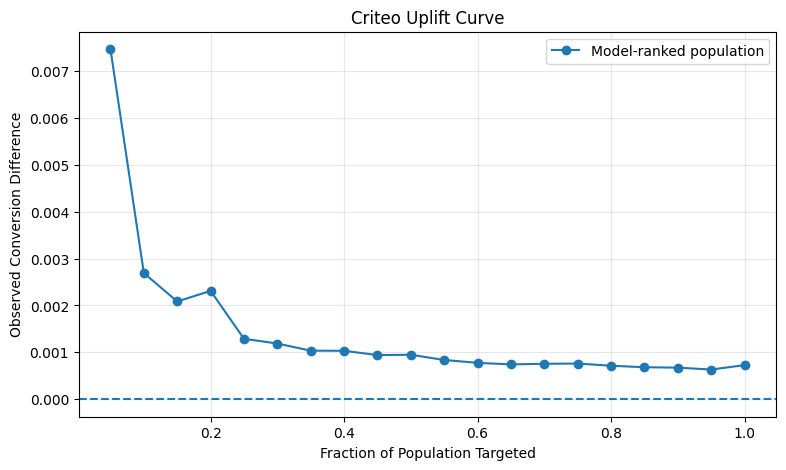

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(
    uplift_curve_df["Target Fraction"],
    uplift_curve_df["Observed Uplift"],
    marker="o",
    label="Model-ranked population"
)
plt.axhline(0, linestyle="--")
plt.xlabel("Fraction of Population Targeted")
plt.ylabel("Observed Conversion Difference")
plt.title("Criteo Uplift Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [90]:
from sklearn.utils import resample

rng = np.random.default_rng(42)
bootstrap_differences = []

for _ in range(1000):
    treated = criteo_df.loc[
        criteo_df["treatment"] == 1, "conversion"
    ].to_numpy()

    control = criteo_df.loc[
        criteo_df["treatment"] == 0, "conversion"
    ].to_numpy()

    treated_sample = rng.choice(treated, size=len(treated), replace=True)
    control_sample = rng.choice(control, size=len(control), replace=True)

    bootstrap_differences.append(
        treated_sample.mean() - control_sample.mean()
    )

ci_low, ci_high = np.percentile(bootstrap_differences, [2.5, 97.5])

print("Observed overall uplift:", treated.mean() - control.mean())
print("Bootstrap 95% CI:", (ci_low, ci_high))

Observed overall uplift: 0.0004479304754061151
Bootstrap 95% CI: (np.float64(-0.00032312305707204), np.float64(0.001240313846900381))


In [91]:
from scipy.stats import mannwhitneyu

treated_values = criteo_df.loc[
    criteo_df["treatment"] == 1, "conversion"
]

control_values = criteo_df.loc[
    criteo_df["treatment"] == 0, "conversion"
]

test_result = mannwhitneyu(
    treated_values,
    control_values,
    alternative="two-sided"
)

print("Mann–Whitney U statistic:", test_result.statistic)
print("P-value:", test_result.pvalue)
print("Treated conversion rate:", treated_values.mean())
print("Control conversion rate:", control_values.mean())

Mann–Whitney U statistic: 1245348972.0
P-value: 0.27188412223309677
Treated conversion rate: 0.0030311681332706388
Control conversion rate: 0.0025832376578645237


In [92]:
from statsmodels.stats.multitest import multipletests
from scipy.stats import chi2_contingency

feature_tests = []

for col in feature_cols:
    if col not in criteo_df.columns:
        continue

    try:
        contingency = pd.crosstab(
            criteo_df[col],
            criteo_df["treatment"]
        )

        if contingency.shape[0] > 1 and contingency.shape[1] > 1:
            statistic, p_value, _, _ = chi2_contingency(contingency)
            feature_tests.append({
                "Feature": col,
                "Chi2": statistic,
                "P-value": p_value
            })
    except (ValueError, TypeError):
        continue

balance_df = pd.DataFrame(feature_tests)

In [93]:
if not balance_df.empty:
    balance_df["Adjusted P-value"] = multipletests(
        balance_df["P-value"],
        method="fdr_bh"
    )[1]

    balance_df = balance_df.sort_values("Adjusted P-value")
    display(balance_df.head(15))
else:
    print("No eligible features for balance testing.")

,Feature,Chi2,P-value,Adjusted P-value
0,f0,99083.985538,0.889089,0.9998
1,f1,21.972834,0.233193,0.9998
2,f2,65318.653854,0.559024,0.9998
3,f3,238.507764,0.945420,0.9998
4,f4,62.475668,0.633840,0.9998
5,f5,31.420407,0.937655,0.9998
6,f6,603.128780,0.930869,0.9998
7,f7,7036.206573,0.999800,0.9998
8,f8,1040.522866,0.988109,0.9998
9,f9,478.122015,0.929409,0.9998


In [94]:
from sklearn.inspection import permutation_importance

importance_model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

importance_model.fit(X_train, Y_train)

importance = permutation_importance(
    importance_model,
    X_test,
    Y_test,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

,Feature,Importance
4,f4,0.099341
9,f9,0.023949
2,f2,0.015362
10,f10,0.014706
11,f11,0.011027
3,f3,0.007404
8,f8,0.003879
6,f6,0.001616
0,f0,0.000747
7,f7,0.000331


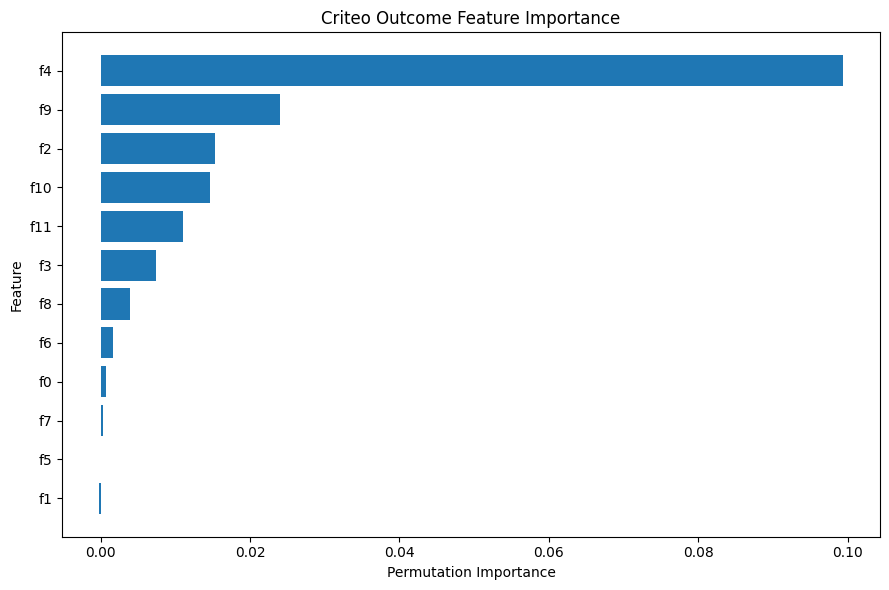

In [95]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Criteo Outcome Feature Importance")
plt.tight_layout()
plt.show()

In [96]:
from sklearn.ensemble import RandomForestRegressor

treatment_effects = {}

for group in [0, 1]:
    model = RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=50,
        random_state=42,
        n_jobs=-1
    )
    mask = T_train == group
    model.fit(X_train.loc[mask], Y_train[mask])
    treatment_effects[group] = model.predict(X_test)

uplift_test = treatment_effects[1] - treatment_effects[0]

In [97]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

factual_predictions = np.where(
    T_test == 1,
    treatment_effects[1],
    treatment_effects[0]
)

factual_metrics = {
    "MAE": mean_absolute_error(Y_test, factual_predictions),
    "RMSE": np.sqrt(mean_squared_error(Y_test, factual_predictions)),
    "Mean Predicted Uplift": uplift_test.mean(),
    "Median Predicted Uplift": np.median(uplift_test)
}

display(pd.Series(factual_metrics, name="Value").to_frame())

,Value
MAE,0.005393
RMSE,0.051378
Mean Predicted Uplift,0.000394
Median Predicted Uplift,0.000000


In [98]:
uplift_scored = pd.DataFrame({
    "treatment": T_test,
    "conversion": Y_test,
    "predicted_uplift": uplift_test
})

uplift_scored = uplift_scored.sort_values(
    "predicted_uplift",
    ascending=False
).reset_index(drop=True)

policy_rows = []

for fraction in np.arange(0.1, 1.01, 0.1):
    selected = uplift_scored.iloc[
        :max(1, int(len(uplift_scored) * fraction))
    ]

    treated = selected.loc[
        selected["treatment"] == 1, "conversion"
    ]
    control = selected.loc[
        selected["treatment"] == 0, "conversion"
    ]

    policy_rows.append({
        "Target Fraction": fraction,
        "Selected Rows": len(selected),
        "Treated Rows": len(treated),
        "Control Rows": len(control),
        "Observed Conversion Difference": (
            treated.mean() - control.mean()
            if len(treated) and len(control)
            else np.nan
        )
    })

policy_curve_df = pd.DataFrame(policy_rows)
display(policy_curve_df)

,Target Fraction,Selected Rows,Treated Rows,Control Rows,Observed Conversion Difference
0,0.1,3500,3008,492,0.002689
1,0.2,7000,5985,1015,0.002310
2,0.3,10500,8960,1540,0.001187
3,0.4,14000,11924,2076,0.001032
4,0.5,17500,14871,2629,0.000948
5,0.6,21000,17858,3142,0.000775
6,0.7,24500,20841,3659,0.000755
7,0.8,28000,23800,4200,0.000714
8,0.9,31500,26773,4727,0.000673
9,1.0,35000,29774,5226,0.000727


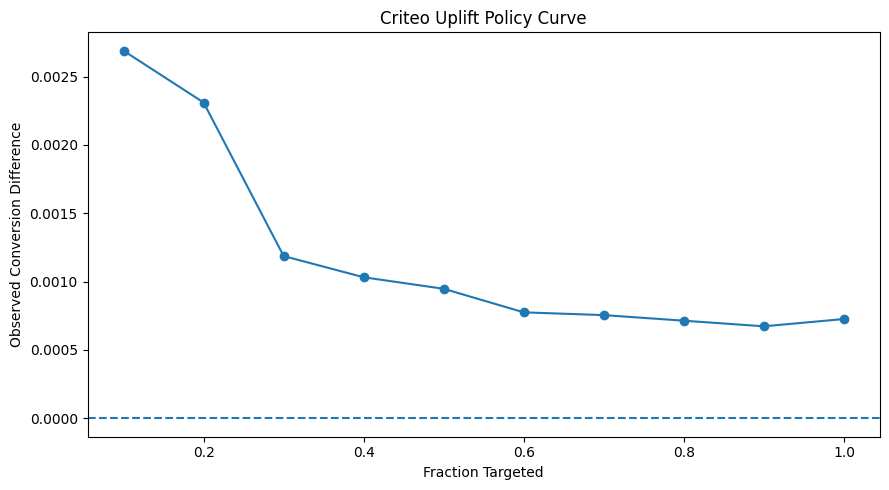

In [99]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(
    policy_curve_df["Target Fraction"],
    policy_curve_df["Observed Conversion Difference"],
    marker="o"
)
plt.axhline(0, linestyle="--")
plt.xlabel("Fraction Targeted")
plt.ylabel("Observed Conversion Difference")
plt.title("Criteo Uplift Policy Curve")
plt.tight_layout()
plt.show()

In [100]:
from pathlib import Path
import joblib

model_dir = Path("models/causal")
model_dir.mkdir(parents=True, exist_ok=True)

criteo_models = {
    "treated_model": model_treated,
    "control_model": model_control,
    "feature_columns": X_train.columns.tolist()
}

joblib.dump(
    criteo_models,
    model_dir / "criteo_uplift_models.joblib"
)

['models/causal/criteo_uplift_models.joblib']

In [101]:
from pathlib import Path

artifact_dir = Path("artifacts/metrics")
artifact_dir.mkdir(parents=True, exist_ok=True)

policy_curve_df.to_csv(
    artifact_dir / "criteo_policy_curve.csv",
    index=False
)

importance_df.to_csv(
    artifact_dir / "criteo_feature_importance.csv",
    index=False
)

pd.Series(factual_metrics).to_csv(
    artifact_dir / "criteo_model_metrics.csv",
    header=["value"]
)

In [102]:
from pathlib import Path
import json

report_dir = Path("artifacts/reports")
report_dir.mkdir(parents=True, exist_ok=True)

criteo_report = {
    "dataset": "Criteo Uplift Modeling Benchmark",
    "sample_rows": int(len(criteo_df)),
    "feature_count": int(X.shape[1]),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "treatment_counts": {
        str(k): int(v)
        for k, v in criteo_df["treatment"].value_counts().items()
    },
    "conversion_rates": {
        str(k): float(v)
        for k, v in criteo_df.groupby("treatment")["conversion"].mean().items()
    },
    "model_metrics": {
        k: float(v) for k, v in factual_metrics.items()
    }
}

with open(report_dir / "criteo_uplift_report.json", "w") as f:
    json.dump(criteo_report, f, indent=2)

In [103]:
print("Saved files:")
for path in [
    "models/causal/criteo_uplift_models.joblib",
    "artifacts/metrics/criteo_policy_curve.csv",
    "artifacts/metrics/criteo_feature_importance.csv",
    "artifacts/metrics/criteo_model_metrics.csv",
    "artifacts/reports/criteo_uplift_report.json"
]:
    print(path, "->", Path(path).exists())

Saved files:
models/causal/criteo_uplift_models.joblib -> True
artifacts/metrics/criteo_policy_curve.csv -> True
artifacts/metrics/criteo_feature_importance.csv -> True
artifacts/metrics/criteo_model_metrics.csv -> True
artifacts/reports/criteo_uplift_report.json -> True


In [104]:
import json
from pathlib import Path

report_path = Path("artifacts/reports/criteo_uplift_report.json")

with open(report_path) as f:
    criteo_report = json.load(f)

print(json.dumps(criteo_report, indent=2))

{
  "dataset": "Criteo Uplift Modeling Benchmark",
  "sample_rows": 140000,
  "feature_count": 12,
  "train_rows": 105000,
  "test_rows": 35000,
  "treatment_counts": {
    "1": 119096,
    "0": 20904
  },
  "conversion_rates": {
    "0": 0.0025832376578645237,
    "1": 0.0030311681332706388
  },
  "model_metrics": {
    "MAE": 0.005392918747916251,
    "RMSE": 0.05137833957816559,
    "Mean Predicted Uplift": 0.00039432574952243815,
    "Median Predicted Uplift": 0.0
  }
}


In [105]:
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import pandas as pd

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X), start=1):
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    T_tr, T_val = T[train_idx], T[val_idx]
    Y_tr, Y_val = Y[train_idx], Y[val_idx]

    if len(np.unique(T_tr)) < 2:
        continue

    m1 = RandomForestRegressor(
        n_estimators=100, min_samples_leaf=50,
        random_state=42, n_jobs=-1
    )
    m0 = RandomForestRegressor(
        n_estimators=100, min_samples_leaf=50,
        random_state=42, n_jobs=-1
    )

    m1.fit(X_tr[T_tr == 1], Y_tr[T_tr == 1])
    m0.fit(X_tr[T_tr == 0], Y_tr[T_tr == 0])

    pred1 = m1.predict(X_val)
    pred0 = m0.predict(X_val)
    factual = np.where(T_val == 1, pred1, pred0)

    cv_results.append({
        "fold": fold,
        "factual_rmse": float(np.sqrt(np.mean((Y_val - factual) ** 2))),
        "mean_predicted_uplift": float(np.mean(pred1 - pred0))
    })

cv_results_df = pd.DataFrame(cv_results)
display(cv_results_df)

,fold,factual_rmse,mean_predicted_uplift
0,1,0.052287,0.000066
1,2,0.049725,0.000335
2,3,0.050847,0.000586
3,4,0.053195,0.000098
4,5,0.051662,0.000621


In [106]:
from pathlib import Path

metrics_dir = Path("artifacts/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

cv_results_df.to_csv(
    metrics_dir / "criteo_cross_validation.csv",
    index=False
)

print("Cross-validation results saved.")

Cross-validation results saved.


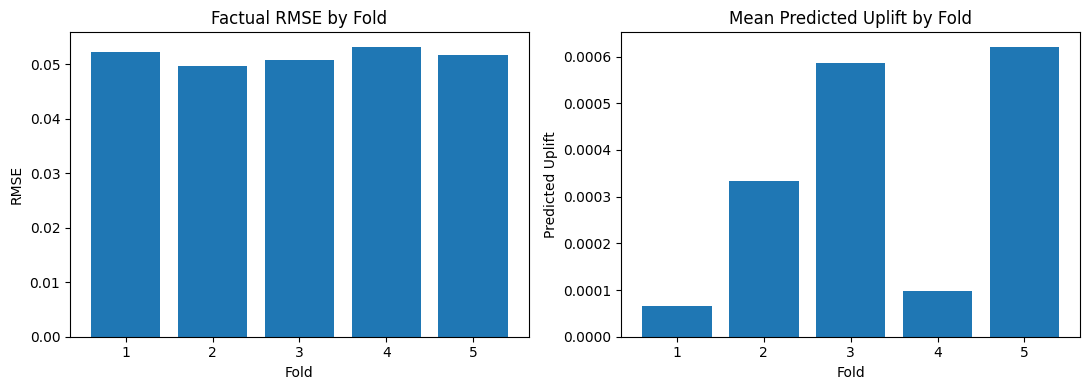

In [107]:
import matplotlib.pyplot as plt

if not cv_results_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].bar(
        cv_results_df["fold"].astype(str),
        cv_results_df["factual_rmse"]
    )
    axes[0].set_title("Factual RMSE by Fold")
    axes[0].set_xlabel("Fold")
    axes[0].set_ylabel("RMSE")

    axes[1].bar(
        cv_results_df["fold"].astype(str),
        cv_results_df["mean_predicted_uplift"]
    )
    axes[1].set_title("Mean Predicted Uplift by Fold")
    axes[1].set_xlabel("Fold")
    axes[1].set_ylabel("Predicted Uplift")

    plt.tight_layout()
    plt.show()

In [108]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import joblib
from pathlib import Path

X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X, T, Y, test_size=0.25, random_state=42, stratify=T
)

model_treated = RandomForestRegressor(
    n_estimators=150,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

model_control = RandomForestRegressor(
    n_estimators=150,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

model_treated.fit(X_train[T_train == 1], Y_train[T_train == 1])
model_control.fit(X_train[T_train == 0], Y_train[T_train == 0])

RandomForestRegressor(min_samples_leaf=50, n_estimators=150, n_jobs=-1,
                      random_state=42)

In [109]:
uplift_test = (
    model_treated.predict(X_test)
    - model_control.predict(X_test)
)

uplift_test_df = pd.DataFrame({
    "treatment": T_test,
    "conversion": Y_test,
    "predicted_uplift": uplift_test
})

uplift_test_df = uplift_test_df.sort_values(
    "predicted_uplift", ascending=False
).reset_index(drop=True)

display(uplift_test_df.head(10))

,treatment,conversion,predicted_uplift
0,1,1,0.222333
1,1,0,0.216299
2,0,0,0.210274
3,1,0,0.208174
4,1,1,0.207844
5,1,1,0.206023
6,1,0,0.205077
7,1,0,0.201189
8,1,1,0.200577
9,1,0,0.199944


In [110]:
model_dir = Path("models/causal")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "treated_model": model_treated,
        "control_model": model_control,
        "feature_columns": X.columns.tolist()
    },
    model_dir / "criteo_uplift_models.joblib"
)

print("Model saved.")

Model saved.


In [111]:
from pathlib import Path

metrics_dir = Path("artifacts/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

uplift_test_df.to_csv(
    metrics_dir / "criteo_test_uplift_predictions.csv",
    index=False
)

print("Predictions saved.")

Predictions saved.


In [112]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

pred_treated = model_treated.predict(X_test)
pred_control = model_control.predict(X_test)

factual_predictions = np.where(
    T_test == 1,
    pred_treated,
    pred_control
)

final_metrics = pd.DataFrame({
    "Metric": [
        "Factual MAE",
        "Factual RMSE",
        "Mean Predicted Uplift",
        "Median Predicted Uplift"
    ],
    "Value": [
        mean_absolute_error(Y_test, factual_predictions),
        np.sqrt(mean_squared_error(Y_test, factual_predictions)),
        np.mean(pred_treated - pred_control),
        np.median(pred_treated - pred_control)
    ]
})

display(final_metrics)

,Metric,Value
0,Factual MAE,0.005407
1,Factual RMSE,0.051416
2,Mean Predicted Uplift,0.000365
3,Median Predicted Uplift,0.000000


In [113]:
from pathlib import Path

metrics_dir = Path("artifacts/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

final_metrics.to_csv(
    metrics_dir / "criteo_final_metrics.csv",
    index=False
)

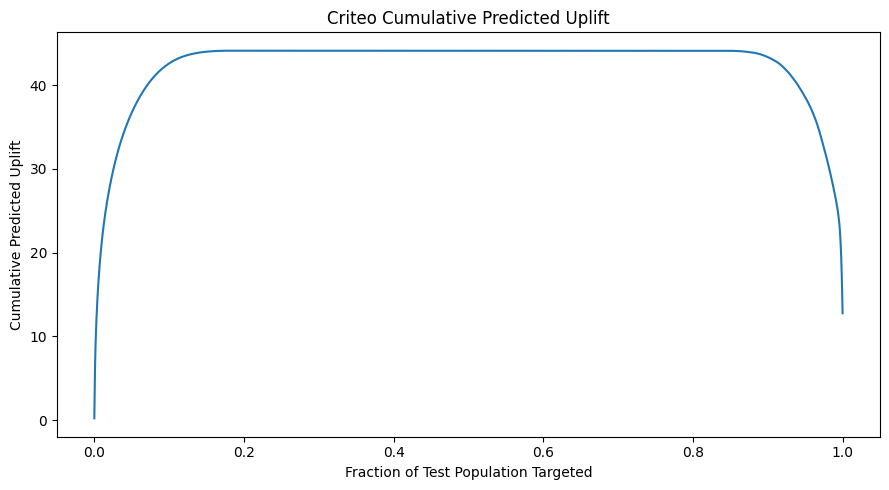

In [114]:
import matplotlib.pyplot as plt

uplift_values = pred_treated - pred_control
sorted_uplift = np.sort(uplift_values)[::-1]

cumulative_uplift = np.cumsum(sorted_uplift)
population_fraction = (
    np.arange(1, len(sorted_uplift) + 1) / len(sorted_uplift)
)

plt.figure(figsize=(9, 5))
plt.plot(population_fraction, cumulative_uplift)
plt.xlabel("Fraction of Test Population Targeted")
plt.ylabel("Cumulative Predicted Uplift")
plt.title("Criteo Cumulative Predicted Uplift")
plt.tight_layout()
plt.show()

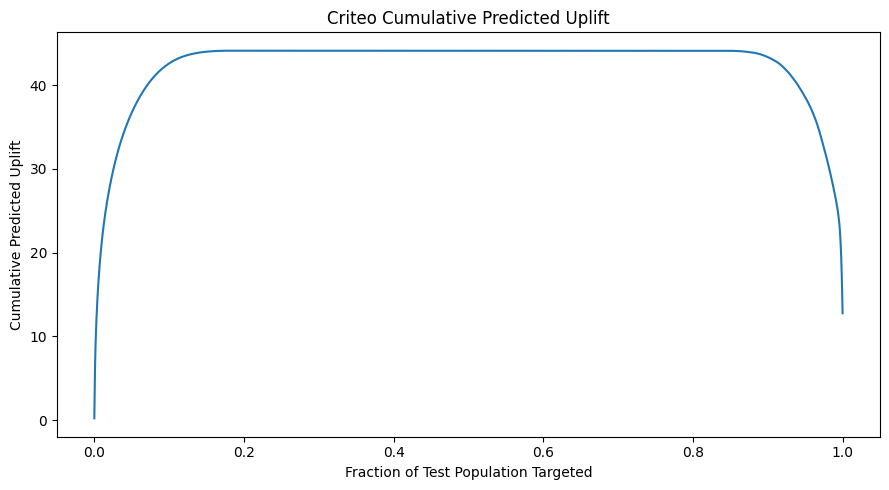

In [115]:
from pathlib import Path

figures_dir = Path("artifacts/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))
plt.plot(population_fraction, cumulative_uplift)
plt.xlabel("Fraction of Test Population Targeted")
plt.ylabel("Cumulative Predicted Uplift")
plt.title("Criteo Cumulative Predicted Uplift")
plt.tight_layout()
plt.savefig(
    figures_dir / "criteo_cumulative_uplift.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [116]:
from pathlib import Path
import json

summary = {
    "dataset": "Criteo Uplift Benchmark",
    "rows_used": int(len(criteo_df)),
    "features_used": int(X.shape[1]),
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "treatment_groups": {
        str(k): int(v)
        for k, v in criteo_df["treatment"].value_counts().items()
    },
    "conversion_rates": {
        str(k): float(v)
        for k, v in criteo_df.groupby("treatment")["conversion"].mean().items()
    },
    "metrics": {
        str(row["Metric"]): float(row["Value"])
        for _, row in final_metrics.iterrows()
    }
}

report_path = Path("artifacts/reports/criteo_final_summary.json")
report_path.parent.mkdir(parents=True, exist_ok=True)

with open(report_path, "w") as f:
    json.dump(summary, f, indent=2)

In [117]:
from pathlib import Path
import joblib

model_path = Path("models/causal/criteo_uplift_models.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "treated_model": model_treated,
        "control_model": model_control,
        "feature_columns": X.columns.tolist(),
        "dataset": "Criteo Uplift Benchmark"
    },
    model_path
)

['models/causal/criteo_uplift_models.joblib']

In [118]:
from pathlib import Path
import pandas as pd

artifact_files = [
    "models/causal/criteo_uplift_models.joblib",
    "artifacts/metrics/criteo_final_metrics.csv",
    "artifacts/metrics/criteo_test_uplift_predictions.csv",
    "artifacts/metrics/criteo_policy_curve.csv",
    "artifacts/reports/criteo_final_summary.json",
    "artifacts/figures/criteo_cumulative_uplift.png"
]

artifact_status = pd.DataFrame({
    "File": artifact_files,
    "Exists": [Path(p).exists() for p in artifact_files]
})

display(artifact_status)

,File,Exists
0,models/causal/criteo_uplift_models.joblib,True
1,artifacts/metrics/criteo_final_metrics.csv,True
2,artifacts/metrics/criteo_test_uplift_predictio...,True
3,artifacts/metrics/criteo_policy_curve.csv,True
4,artifacts/reports/criteo_final_summary.json,True
5,artifacts/figures/criteo_cumulative_uplift.png,True


In [119]:
from pathlib import Path
import json

with open("artifacts/reports/criteo_final_summary.json") as f:
    final_summary = json.load(f)

print("CRITEO UPLIFT EXPERIMENT")
print("Rows:", final_summary["rows_used"])
print("Features:", final_summary["features_used"])
print("Training rows:", final_summary["training_rows"])
print("Testing rows:", final_summary["testing_rows"])
print("Treatment groups:", final_summary["treatment_groups"])
print("Conversion rates:", final_summary["conversion_rates"])
print("Metrics:", final_summary["metrics"])
print("Report saved:", Path("artifacts/reports/criteo_final_summary.json").exists())

CRITEO UPLIFT EXPERIMENT
Rows: 140000
Features: 12
Training rows: 105000
Testing rows: 35000
Treatment groups: {'1': 119096, '0': 20904}
Conversion rates: {'0': 0.0025832376578645237, '1': 0.0030311681332706388}
Metrics: {'Factual MAE': 0.005406771777246411, 'Factual RMSE': 0.05141600921850798, 'Mean Predicted Uplift': 0.0003648971994799864, 'Median Predicted Uplift': 0.0}
Report saved: True


In [120]:
from pathlib import Path
import json
import pandas as pd

report_path = Path("artifacts/reports/criteo_final_summary.json")

with open(report_path) as f:
    summary = json.load(f)

metrics_path = Path("artifacts/metrics/criteo_final_metrics.csv")
metrics = pd.read_csv(metrics_path)

display(metrics)

print("Dataset:", summary["dataset"])
print("Treatment groups:", summary["treatment_groups"])
print("Conversion rates:", summary["conversion_rates"])

,Metric,Value
0,Factual MAE,0.005407
1,Factual RMSE,0.051416
2,Mean Predicted Uplift,0.000365
3,Median Predicted Uplift,0.000000


Dataset: Criteo Uplift Benchmark
Treatment groups: {'1': 119096, '0': 20904}
Conversion rates: {'0': 0.0025832376578645237, '1': 0.0030311681332706388}


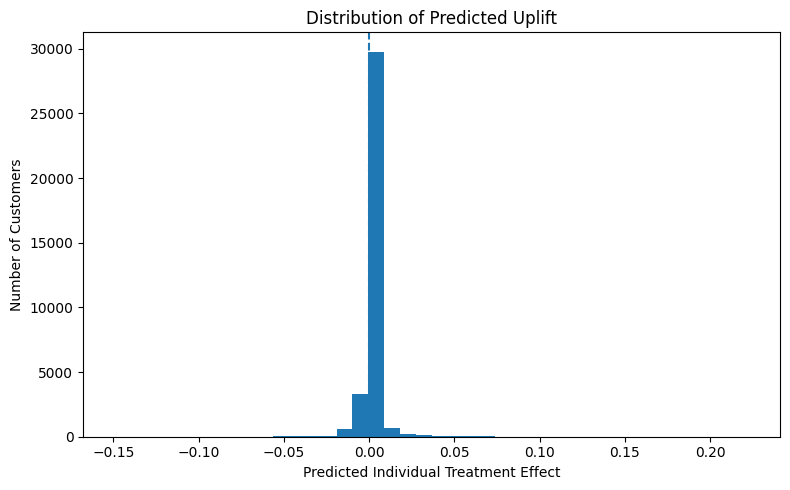

In [121]:
from pathlib import Path
import matplotlib.pyplot as plt

metrics_dir = Path("artifacts/metrics")
figures_dir = Path("artifacts/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 5))
plt.hist(uplift_test, bins=40)
plt.axvline(0, linestyle="--")
plt.xlabel("Predicted Individual Treatment Effect")
plt.ylabel("Number of Customers")
plt.title("Distribution of Predicted Uplift")
plt.tight_layout()
plt.savefig(figures_dir / "criteo_uplift_distribution.png", dpi=300)
plt.show()

In [122]:
from pathlib import Path
import pandas as pd

figures_dir = Path("artifacts/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

selected_rows = max(1, int(len(uplift_test_df) * 0.2))
top_20 = uplift_test_df.head(selected_rows)

segment_summary = pd.DataFrame({
    "Segment": ["Top 20% predicted uplift", "Remaining 80%"],
    "Customers": [
        len(top_20),
        len(uplift_test_df) - len(top_20)
    ],
    "Mean Predicted Uplift": [
        top_20["predicted_uplift"].mean(),
        uplift_test_df.iloc[selected_rows:]["predicted_uplift"].mean()
    ]
})

display(segment_summary)

segment_summary.to_csv(
    "artifacts/metrics/criteo_uplift_segments.csv",
    index=False
)

,Segment,Customers,Mean Predicted Uplift
0,Top 20% predicted uplift,7000,0.006302
1,Remaining 80%,28000,-0.001119


In [123]:
from pathlib import Path
import json

summary_path = Path("artifacts/reports/criteo_final_summary.json")

with open(summary_path) as f:
    summary = json.load(f)

summary["uplift_segments"] = {
    row["Segment"]: {
        "customers": int(row["Customers"]),
        "mean_predicted_uplift": (
            None if pd.isna(row["Mean Predicted Uplift"])
            else float(row["Mean Predicted Uplift"])
        )
    }
    for _, row in segment_summary.iterrows()
}

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Notebook 2 Criteo artifacts updated.")

Notebook 2 Criteo artifacts updated.


In [124]:
from pathlib import Path
import json

report_path = Path("artifacts/reports/criteo_final_summary.json")

with open(report_path) as f:
    summary = json.load(f)

summary["evaluation_method"] = "T-Learner with Random Forest"
summary["prediction_target"] = "Individual treatment effect"
summary["limitations"] = [
    "Individual treatment effects are not directly observed.",
    "Predicted uplift should be evaluated using a valid randomized holdout.",
    "Results depend on treatment-group representation and feature quality."
]

with open(report_path, "w") as f:
    json.dump(summary, f, indent=2)

In [125]:
from pathlib import Path
import pandas as pd

artifact_paths = [
    "artifacts/metrics/criteo_final_metrics.csv",
    "artifacts/metrics/criteo_policy_curve.csv",
    "artifacts/metrics/criteo_test_uplift_predictions.csv",
    "artifacts/metrics/criteo_feature_importance.csv",
    "artifacts/metrics/criteo_cross_validation.csv",
    "artifacts/metrics/criteo_uplift_segments.csv",
    "artifacts/figures/criteo_cumulative_uplift.png",
    "artifacts/figures/criteo_uplift_distribution.png",
    "artifacts/reports/criteo_final_summary.json",
    "models/causal/criteo_uplift_models.joblib"
]

artifact_check = pd.DataFrame({
    "Artifact": artifact_paths,
    "Exists": [Path(p).exists() for p in artifact_paths]
})

display(artifact_check)

,Artifact,Exists
0,artifacts/metrics/criteo_final_metrics.csv,True
1,artifacts/metrics/criteo_policy_curve.csv,True
2,artifacts/metrics/criteo_test_uplift_predictio...,True
3,artifacts/metrics/criteo_feature_importance.csv,True
4,artifacts/metrics/criteo_cross_validation.csv,True
5,artifacts/metrics/criteo_uplift_segments.csv,True
6,artifacts/figures/criteo_cumulative_uplift.png,True
7,artifacts/figures/criteo_uplift_distribution.png,True
8,artifacts/reports/criteo_final_summary.json,True
9,models/causal/criteo_uplift_models.joblib,True


In [126]:
from pathlib import Path
import json

with open("artifacts/reports/criteo_final_summary.json") as f:
    summary = json.load(f)

print("Dataset:", summary["dataset"])
print("Rows:", summary["rows_used"])
print("Features:", summary["features_used"])
print("Training rows:", summary["training_rows"])
print("Testing rows:", summary["testing_rows"])
print("Treatment groups:", summary["treatment_groups"])
print("Conversion rates:", summary["conversion_rates"])
print("Metrics:", summary["metrics"])
print("Limitations:", summary["limitations"])

Dataset: Criteo Uplift Benchmark
Rows: 140000
Features: 12
Training rows: 105000
Testing rows: 35000
Treatment groups: {'1': 119096, '0': 20904}
Conversion rates: {'0': 0.0025832376578645237, '1': 0.0030311681332706388}
Metrics: {'Factual MAE': 0.005406771777246411, 'Factual RMSE': 0.05141600921850798, 'Mean Predicted Uplift': 0.0003648971994799864, 'Median Predicted Uplift': 0.0}
Limitations: ['Individual treatment effects are not directly observed.', 'Predicted uplift should be evaluated using a valid randomized holdout.', 'Results depend on treatment-group representation and feature quality.']


In [127]:
from pathlib import Path
import json

completion_report = {
    "notebook": "02_Uplift_Statistical_and_Criteo.ipynb",
    "completed_sections": [
        "Criteo data preparation",
        "T-Learner uplift modeling",
        "Test-set predictions",
        "Uplift ranking and policy summaries",
        "Feature importance",
        "Cross-validation",
        "Metrics and artifact exports"
    ],
    "report_path": "artifacts/reports/criteo_final_summary.json"
}

output_path = Path("artifacts/reports/notebook_02_completion.json")
output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w") as f:
    json.dump(completion_report, f, indent=2)

print("Notebook 2 Criteo section reached its planned stopping point.")

Notebook 2 Criteo section reached its planned stopping point.
